# Exploratory Data Analysis: ToxValDB_v9.7.0_Cleaned
This notebook performs exploratory data analysis and data cleaning on the ToxValDB dataset.
It identifies and removes biological outliers, plant records, and suspicious or erroneous values
based on physical and biological consistency checks, producing a final cleaned dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Ensure all columns are shown when displaying DataFrames
pd.set_option('display.max_columns', None)

## 1. Load Data
We load the TSV file and take a first look at the structure.

In [ ]:
file_path = '../outputs/ToxValDB_v9.7.0_Cleaned_00.tsv'
df = pd.read_csv(file_path, sep='\t')

print(f"Original shape of dataset: {df.shape}")
df.head()

Original shape of dataset: (479533, 34)


,DTXSID,CASRN,NAME,SOURCE,SUB_SOURCE,TOXVAL_TYPE,TOXVAL_SUBTYPE,TOXVAL_TYPE_SUPERCATEGORY,QUALIFIER,TOXVAL_NUMERIC,TOXVAL_UNITS,RISK_ASSESSMENT_CLASS,STUDY_TYPE,STUDY_DURATION_CLASS,STUDY_DURATION_VALUE,STUDY_DURATION_UNITS,SPECIES_COMMON,STRAIN,LATIN_NAME,SPECIES_SUPERCATEGORY,SEX,GENERATION,LIFESTAGE,EXPOSURE_ROUTE,EXPOSURE_METHOD,EXPOSURE_FORM,MEDIA,TOXICOLOGICAL_EFFECT,TOXICOLOGICAL_EFFECT_CATEGORY,EXPERIMENTAL_RECORD,STUDY_GROUP,YEAR,ORIGINAL_YEAR,MATRIX_GUIDELINE
0,DTXSID3021774,83-32-9,Acenaphthene,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.600000,mg/kg-day,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,oral,-,-,-,hepatic mice,-,not experimental,ATSDR MRLs:15446843:-:--,1995,1995,NaN
1,DTXSID8021482,67-64-1,Acetone,ATSDR MRLs,-,MRL,acute,Toxicity Value,=,19.003800,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,neurological,-,not experimental,ATSDR MRLs:15446844:-:--,2022,2022,NaN
2,DTXSID8021482,67-64-1,Acetone,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.600000,mg/kg-day,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,oral,-,-,-,hematological rats,-,not experimental,ATSDR MRLs:15446845:-:--,2022,2022,NaN
3,DTXSID5020023,107-02-8,Acrolein,ATSDR MRLs,-,MRL,acute,Toxicity Value,=,0.006879,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,respiratory,-,not experimental,ATSDR MRLs_dup_-_15446846_15446847:-:--,2007,2007,NaN
4,DTXSID5020023,107-02-8,Acrolein,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.000092,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,respiratory rats,-,not experimental,ATSDR MRLs_dup_-_15446846_15446847:-:--,2007,2007,NaN


### 2.2 Re-check Missing Values and Data Types
After replacement, we redefine numerical and categorical columns as some placeholders (like `-`) might have forced numerical columns to be objects.

,Dtype,Unique Values,Missing Values,Percentage Missing
DTXSID,object,41855,0,0.00
CASRN,object,41840,0,0.00
NAME,object,42058,0,0.00
SOURCE,object,62,0,0.00
SUB_SOURCE,object,171,0,0.00
TOXVAL_TYPE,object,249,0,0.00
TOXVAL_SUBTYPE,object,161,0,0.00
TOXVAL_TYPE_SUPERCATEGORY,object,5,0,0.00
QUALIFIER,object,7,0,0.00
TOXVAL_NUMERIC,float64,19455,0,0.00


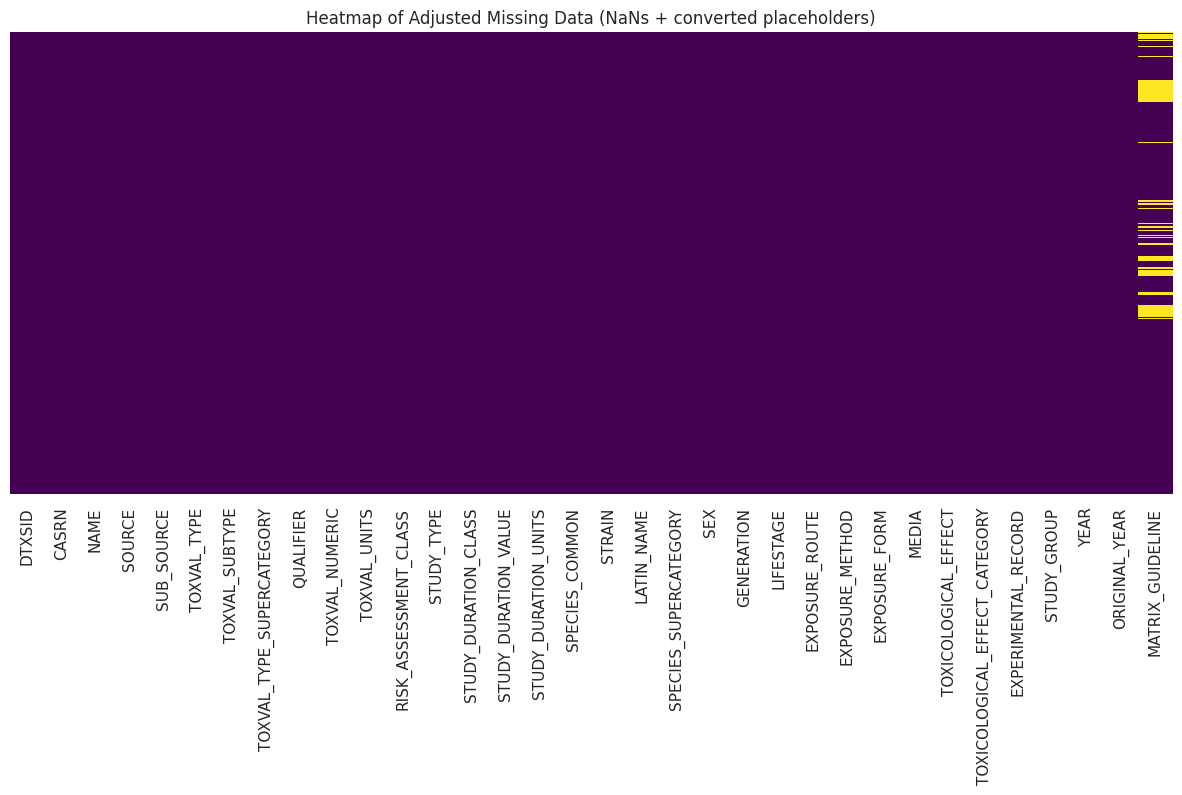

In [3]:
# Attempt to infer better types after removing placeholders
df = df.apply(lambda col: pd.to_numeric(col, errors='coerce').fillna(col))

info_df = pd.DataFrame({
    'Dtype': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum(),
    'Percentage Missing': (df.isnull().sum() / len(df) * 100).round(2)
})
display(info_df)

# Visualize adjusted missing data
plt.figure(figsize=(15, 6))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title("Heatmap of Adjusted Missing Data (NaNs + converted placeholders)")
plt.show()

## 3. Univariate Analysis
We analyze columns based on their updated data type.

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['TOXVAL_NUMERIC', 'STUDY_DURATION_VALUE']
Categorical columns: ['DTXSID', 'CASRN', 'NAME', 'SOURCE', 'SUB_SOURCE', 'TOXVAL_TYPE', 'TOXVAL_SUBTYPE', 'TOXVAL_TYPE_SUPERCATEGORY', 'QUALIFIER', 'TOXVAL_UNITS', 'RISK_ASSESSMENT_CLASS', 'STUDY_TYPE', 'STUDY_DURATION_CLASS', 'STUDY_DURATION_UNITS', 'SPECIES_COMMON', 'STRAIN', 'LATIN_NAME', 'SPECIES_SUPERCATEGORY', 'SEX', 'GENERATION', 'LIFESTAGE', 'EXPOSURE_ROUTE', 'EXPOSURE_METHOD', 'EXPOSURE_FORM', 'MEDIA', 'TOXICOLOGICAL_EFFECT', 'TOXICOLOGICAL_EFFECT_CATEGORY', 'EXPERIMENTAL_RECORD', 'STUDY_GROUP', 'YEAR', 'ORIGINAL_YEAR', 'MATRIX_GUIDELINE']


## 5. Biological Outlier Detection: Study Duration vs Life Expectancy
Certain study durations might exceed the biological lifespan of the species involved (e.g., a Rat with a study of 80 years).

In [5]:
# Mapping of Species to estimated Max Lifespan in YEARS
lifespan_map = {
    'Rat': 4,
    'Mouse': 4,
    'Rabbit': 12,
    'European Rabbit': 12,
    'Human': 120,
    'Dog': 18,
    'Guinea Pig': 8,
    'Monkey': 40,
    'Rhesus Macaque': 40,
    'Cat': 25,
    'Hamster': 4,
    'Pig': 20,
    'Mink': 10,
    'American Mink': 10,
    'Gerbil': 5,
    'Japanese Quail': 3,
    'Chicken': 8,
    'Sheep': 12,
    'Zebra Danio': 5,
    'Northern Bobwhite Quail': 8,
    'Cow Family': 20
}

# Conversion factor to standardize EVERYTHING to years
unit_to_years = {
    'years': 1.0,
    'year': 1.0,
    'months': 1/12,
    'month': 1/12,
    'weeks': 1/52.17,
    'week': 1/52.17,
    'days': 1/365.25,
    'day': 1/365.25,
    'hours': 1/(24*365.25),
    'minutes': 1/(60*24*365.25),
    'generation': 1.0 # conservatively assume 1 generation <= max lifespan
}

if 'STUDY_DURATION_VALUE' in df.columns and 'STUDY_DURATION_UNITS' in df.columns:
    # Create standardized column for comparison
    df['STUDY_DURATION_YEARS'] = df.apply(
        lambda row: row['STUDY_DURATION_VALUE'] * unit_to_years.get(str(row['STUDY_DURATION_UNITS']).lower(), 0) 
        if pd.notnull(row['STUDY_DURATION_VALUE']) else np.nan, 
        axis=1
    )
    
    # Mark outliers
    def is_bio_outlier(row):
        species = row['SPECIES_COMMON']
        dur_years = row['STUDY_DURATION_YEARS']
        if pd.isnull(species) or pd.isnull(dur_years): return False
        
        # Approximate check for multi-species strings (take max if multiple)
        if ',' in str(species):
            parts = [p.strip() for p in str(species).split(',')]
            limit = max([lifespan_map.get(p, 100) for p in parts])
        else:
            limit = lifespan_map.get(species, 100) # Default to 100 for unknown species
            
        return dur_years > limit

    bio_outliers = df[df.apply(is_bio_outlier, axis=1)]
    
    print(f"Detected {len(bio_outliers)} biological outliers for STUDY_DURATION (Duration > Species Lifespan).")
    if len(bio_outliers) > 0:
        display(bio_outliers.head(10))

Detected 8 biological outliers for STUDY_DURATION (Duration > Species Lifespan).


,DTXSID,CASRN,NAME,SOURCE,SUB_SOURCE,TOXVAL_TYPE,TOXVAL_SUBTYPE,TOXVAL_TYPE_SUPERCATEGORY,QUALIFIER,TOXVAL_NUMERIC,TOXVAL_UNITS,RISK_ASSESSMENT_CLASS,STUDY_TYPE,STUDY_DURATION_CLASS,STUDY_DURATION_VALUE,STUDY_DURATION_UNITS,SPECIES_COMMON,STRAIN,LATIN_NAME,SPECIES_SUPERCATEGORY,SEX,GENERATION,LIFESTAGE,EXPOSURE_ROUTE,EXPOSURE_METHOD,EXPOSURE_FORM,MEDIA,TOXICOLOGICAL_EFFECT,TOXICOLOGICAL_EFFECT_CATEGORY,EXPERIMENTAL_RECORD,STUDY_GROUP,YEAR,ORIGINAL_YEAR,MATRIX_GUIDELINE,STUDY_DURATION_YEARS
3066,DTXSID3020203,106-99-0,"1,3-Butadiene",Cal OEHHA REL derivations,-,BMC (05),-,Dose Response Summary Value,=,3.09731,mg/m3,-,chronic,chronic,103.0,months,Mouse,B6C3F1,Mus musculus,Mammals,M/F,-,-,inhalation,discontinuous inhalation,-,-,increased incidence of ovarian atrophy,-,experimental,Cal OEHHA REL derivations:15952007:M/F:--,2000.0,2000.0,OECD 452,8.583333
113022,DTXSID4027866,25340-17-4,Diethylbenzene,ECHA IUCLID,Repeated Dose Toxicity Inhalation,NOAEL,-,Dose Response Summary Value,=,190.00000,mg/m3,-,chronic,chronic,64.0,months,Rat,Sprague Dawley,Rattus norvegicus,Mammals,M/F,-,-,inhalation,whole body,-,-,-,-,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Inhalat...,1997.0,1997.0,OECD 452,5.333333
133959,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOAEL,-,Dose Response Summary Value,=,300.00000,mg/kg-day,-,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2001.0,2001.0,OECD 452,86.313484
133960,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,-,Dose Response Summary Value,=,30.00000,mg/kg-day,-,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2001.0,2001.0,OECD 452,86.313484
137846,DTXSID50442471,118289-55-7,"6-Chloro-5-(2-chloroethyl)-1,3-dihydro-2H-indo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,-,Dose Response Summary Value,=,150.00000,mg/kg-day,-,chronic,chronic,6.0,years,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,-,-,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,1997.0,1997.0,OECD 452,6.000000
137847,DTXSID50442471,118289-55-7,"6-Chloro-5-(2-chloroethyl)-1,3-dihydro-2H-indo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,-,Dose Response Summary Value,=,15.00000,mg/kg-day,-,chronic,chronic,6.0,years,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,-,-,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,1997.0,1997.0,OECD 452,6.000000
146481,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOAEL,-,Dose Response Summary Value,=,300.00000,mg/kg-day,-,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2009.0,2009.0,OECD 452,86.313484
146482,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,-,Dose Response Summary Value,=,30.00000,mg/kg-day,-,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,-,-,oral,gavage,-,-,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2009.0,2009.0,OECD 452,86.313484


## 6. Categorical Columns Analysis

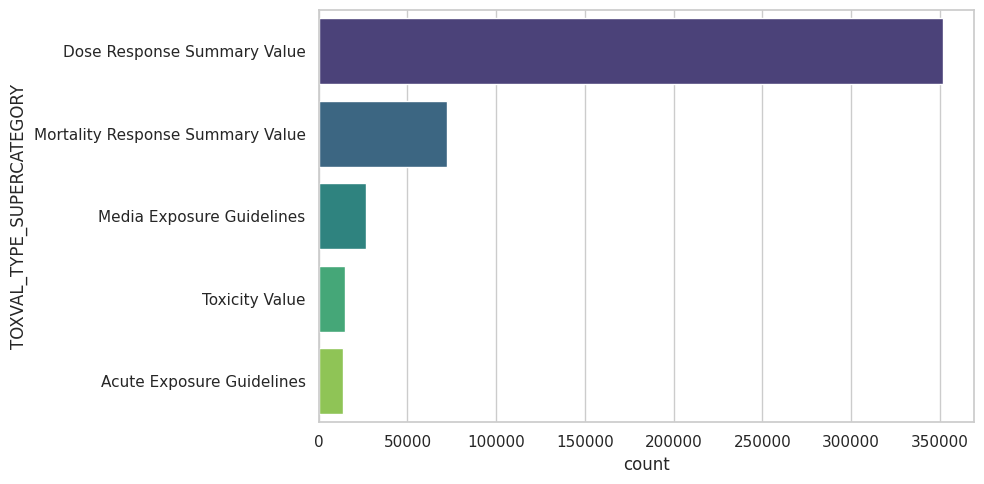

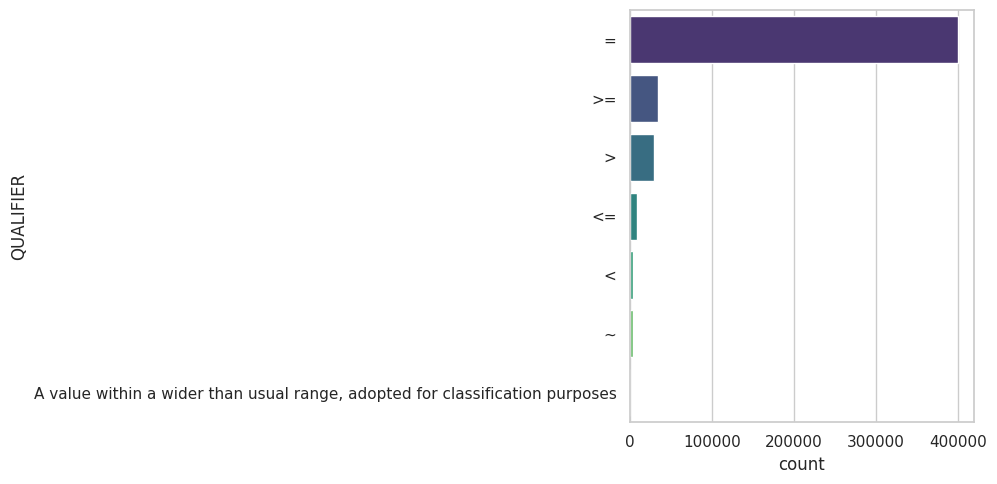

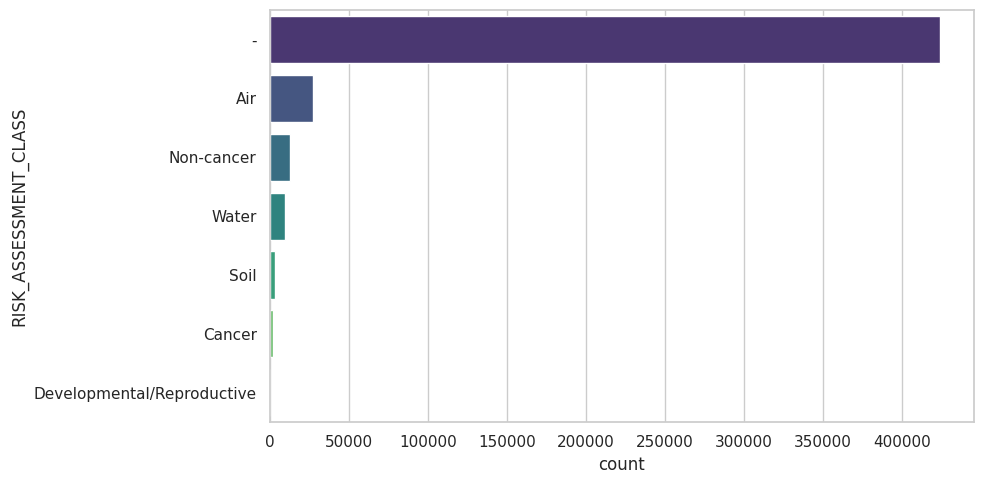

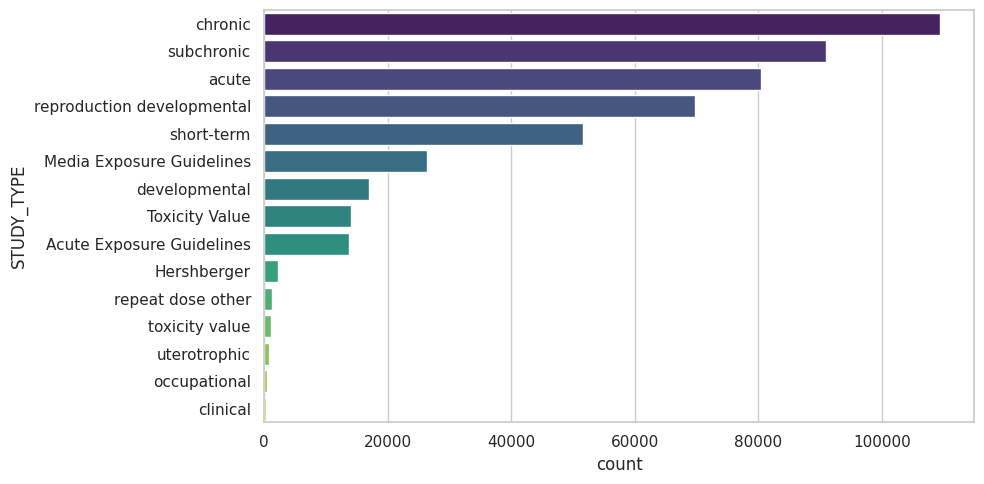

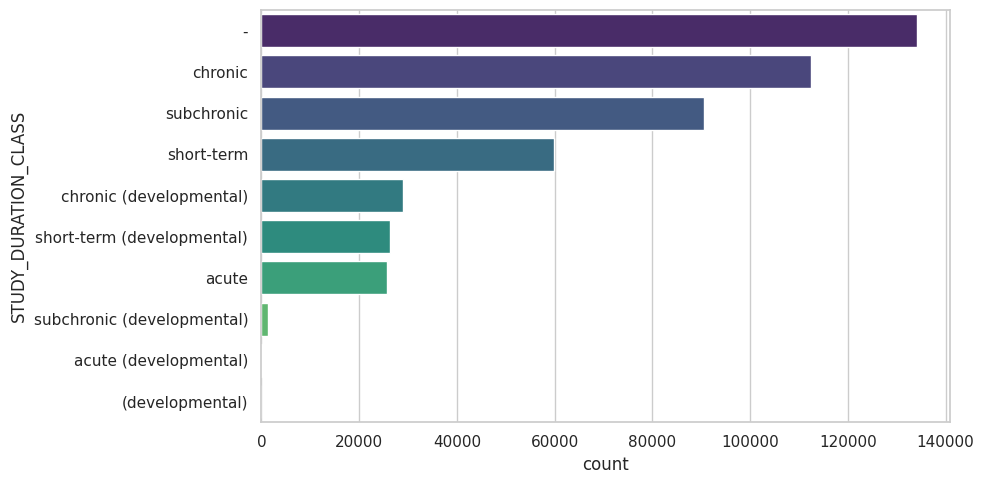

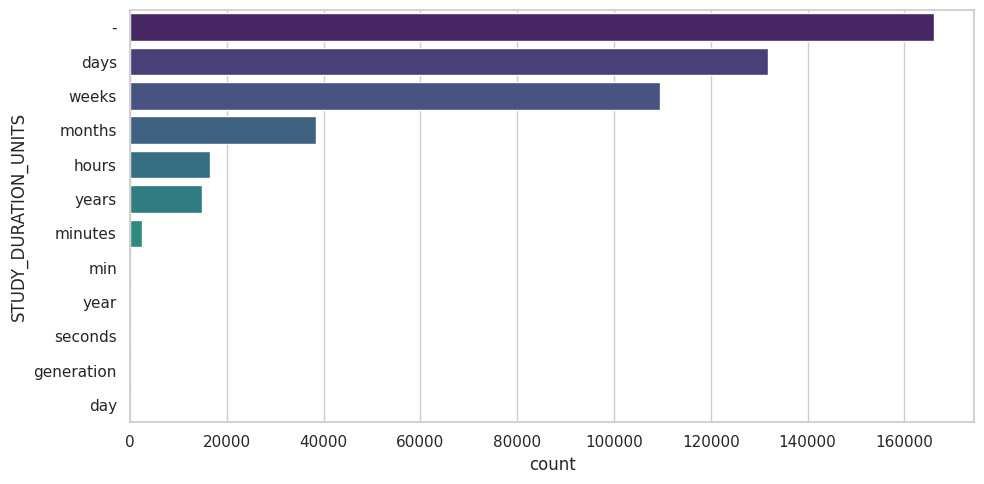

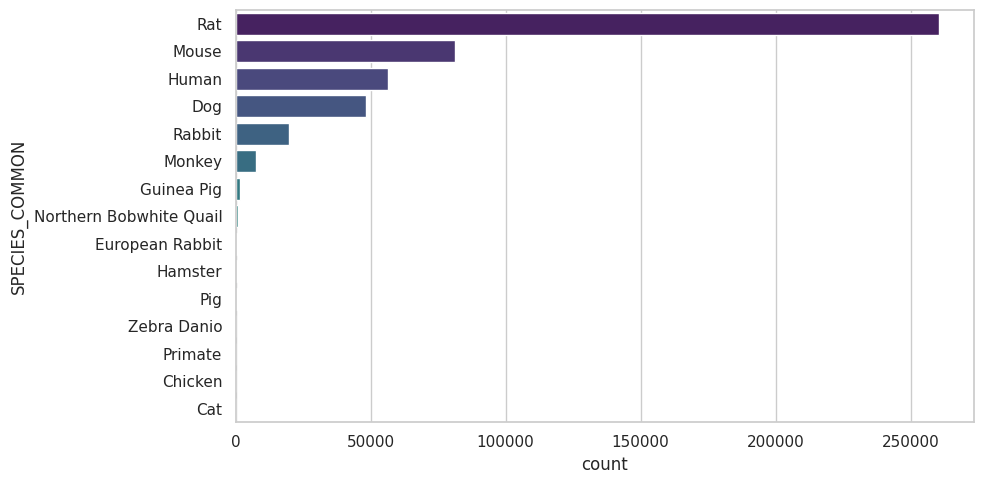

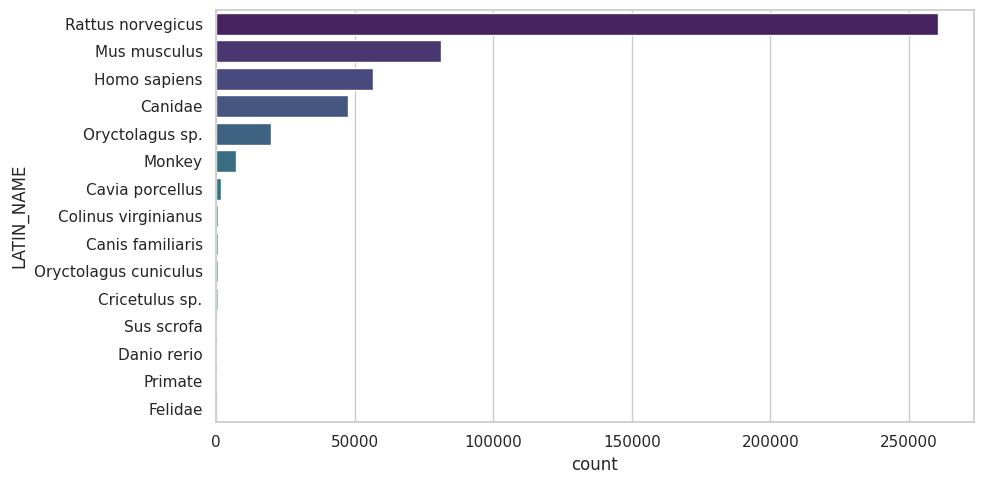

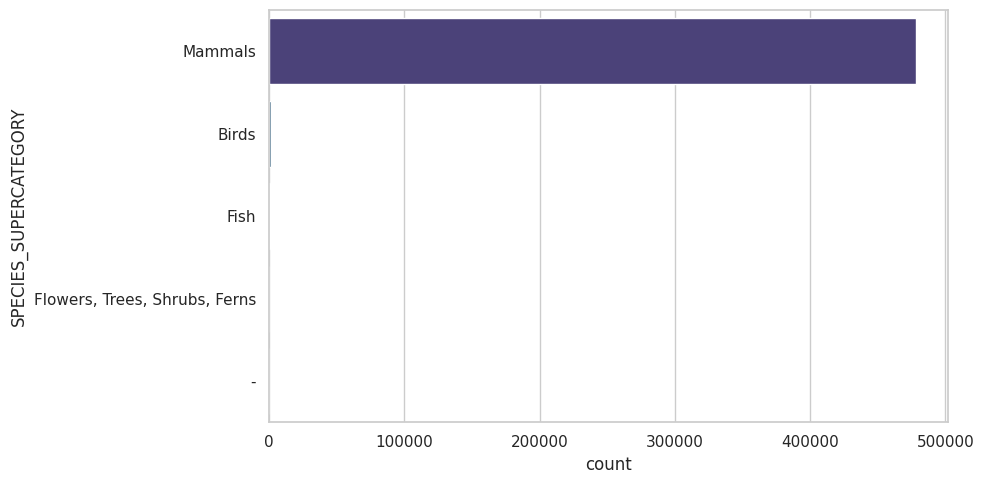

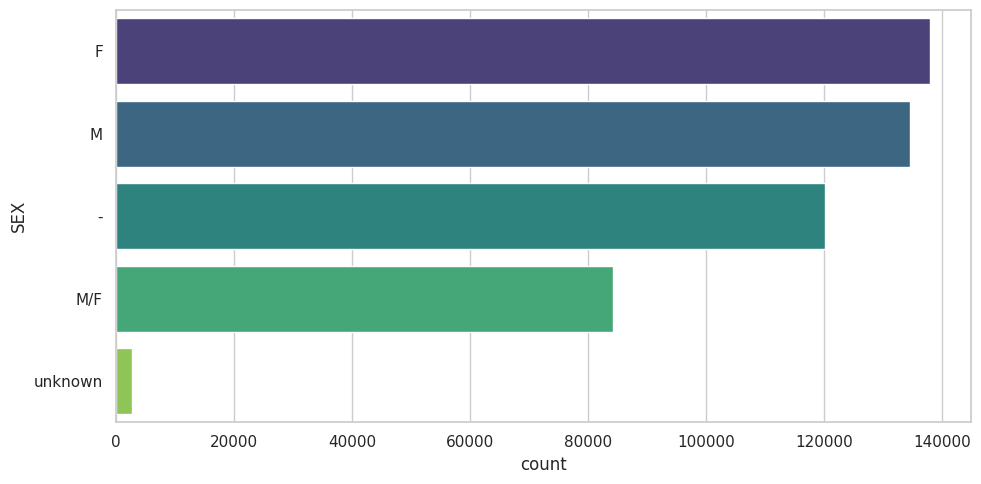

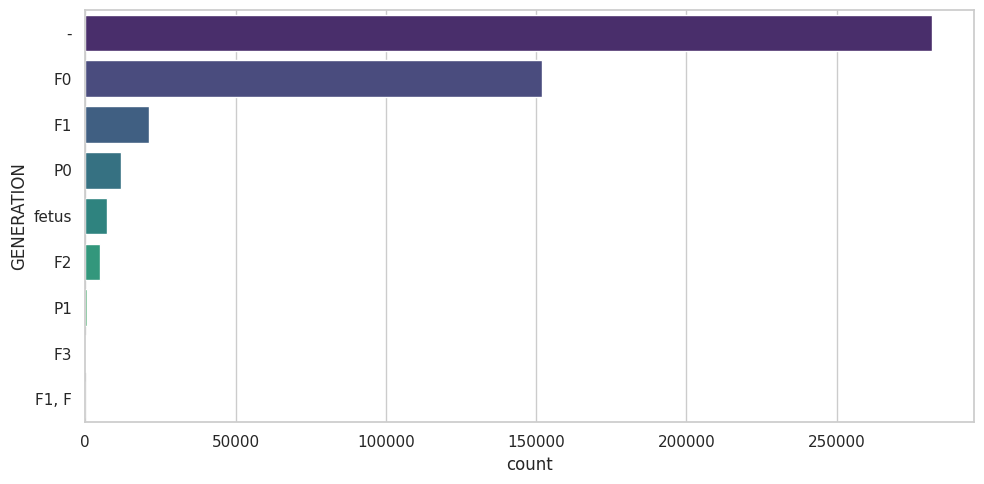

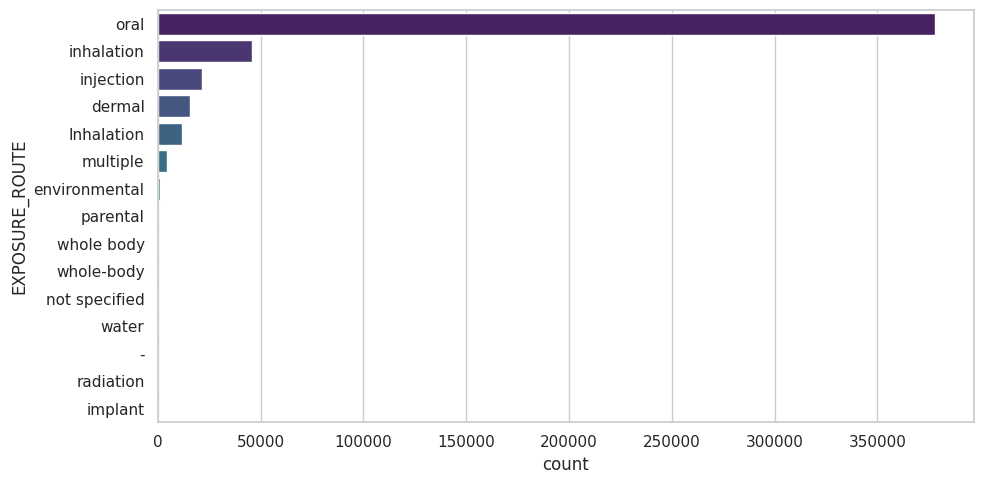

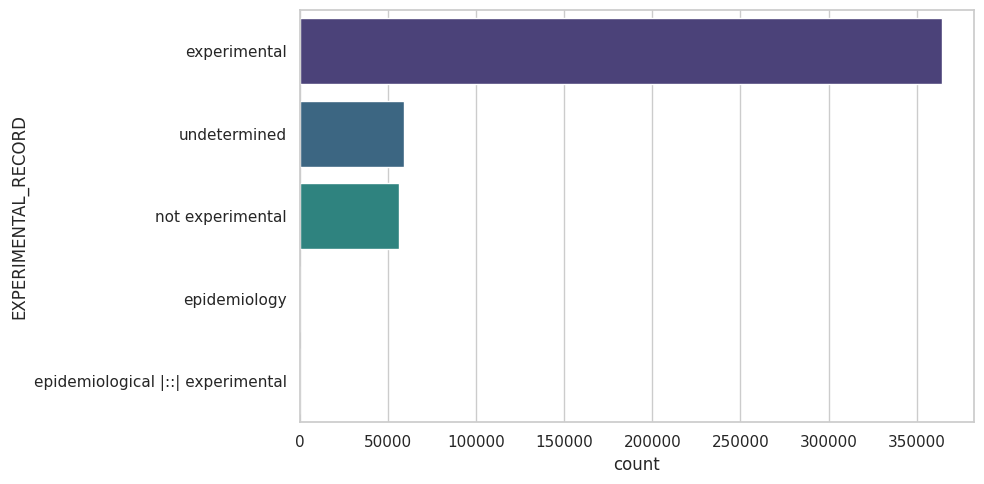

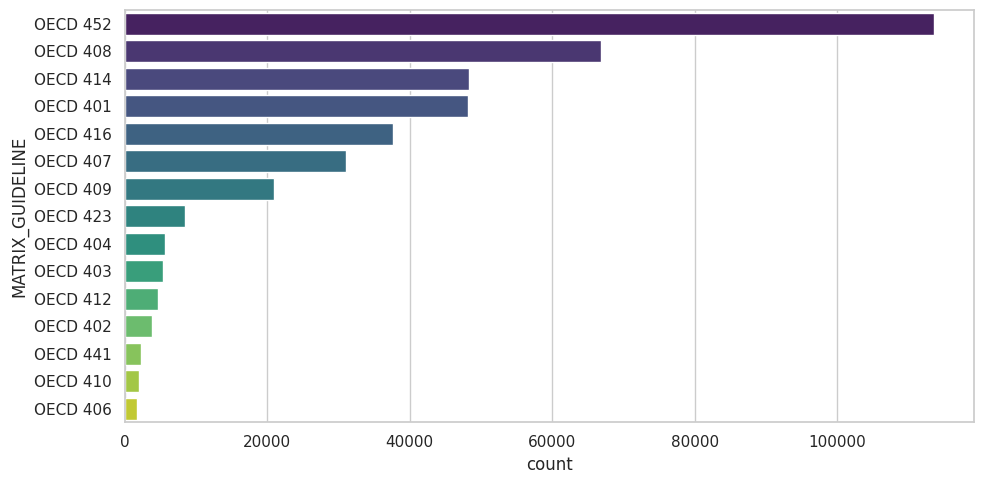

In [6]:
# Filter for columns with reasonable number of categories < 50
cat_to_plot = [c for c in categorical_cols if df[c].nunique() < 50]

for col in cat_to_plot:
    if df[col].nunique() == 0: continue
    
    plt.figure(figsize=(10, 5))
    order = df[col].value_counts().iloc[:15].index
    sns.countplot(data=df, y=col, order=order, palette="viridis")
    plt.tight_layout()
    plt.show()

## 7. Bivariate Analysis: Categorical vs Numerical
We examine how numerical values are distributed across different units and exposure routes.

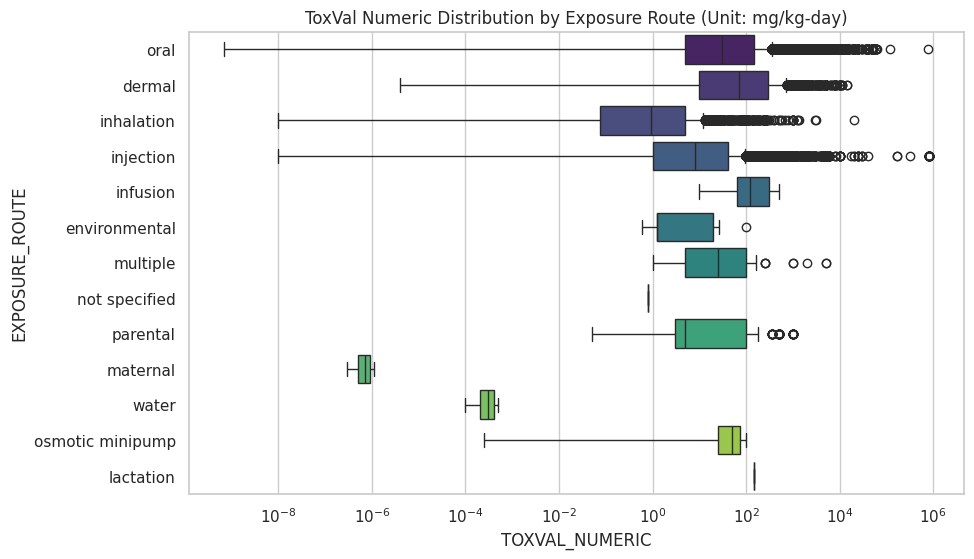

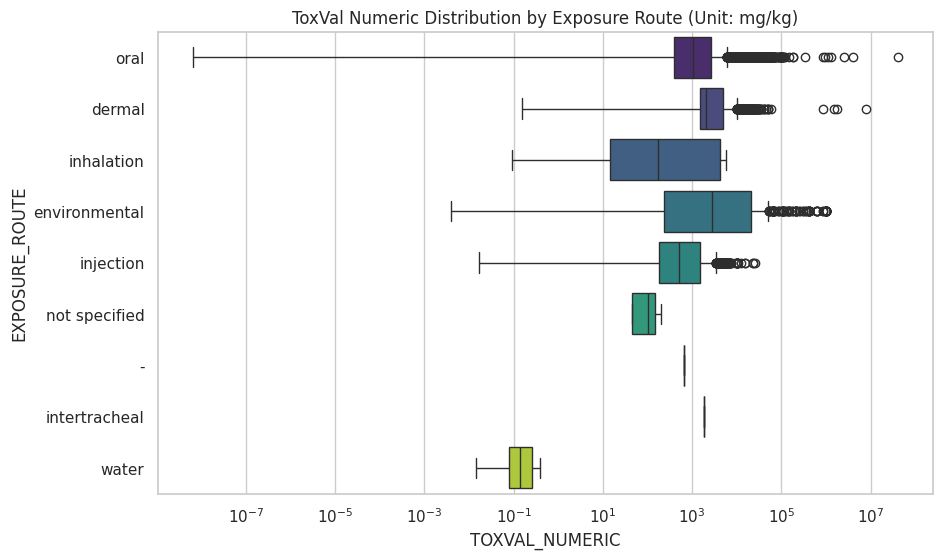

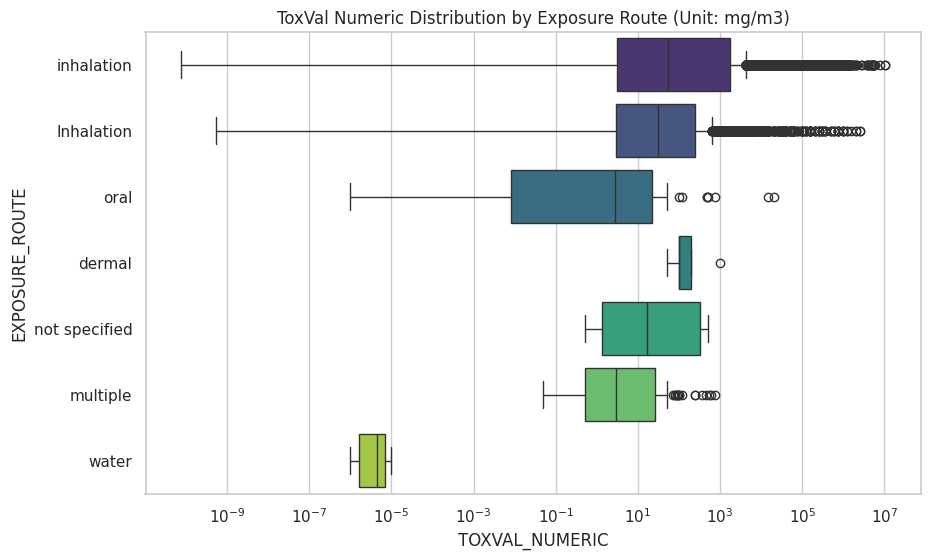

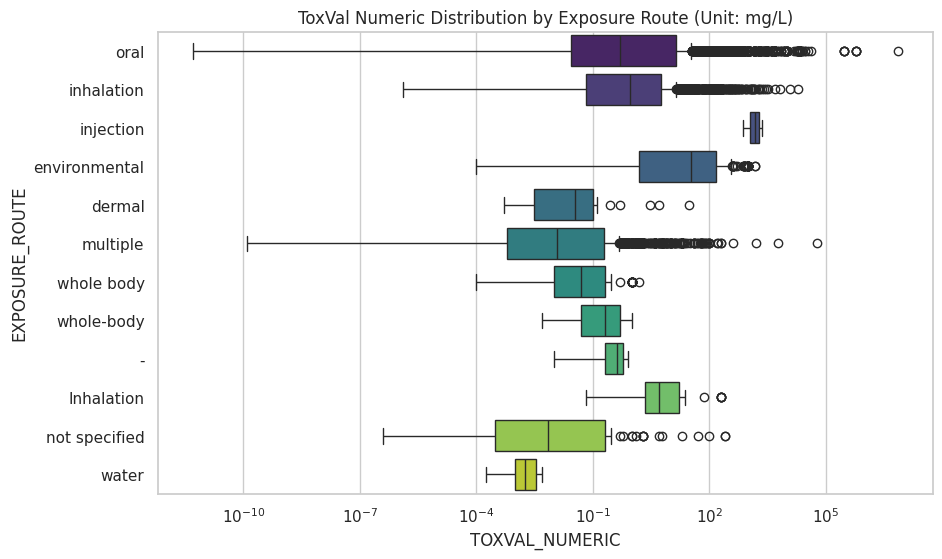

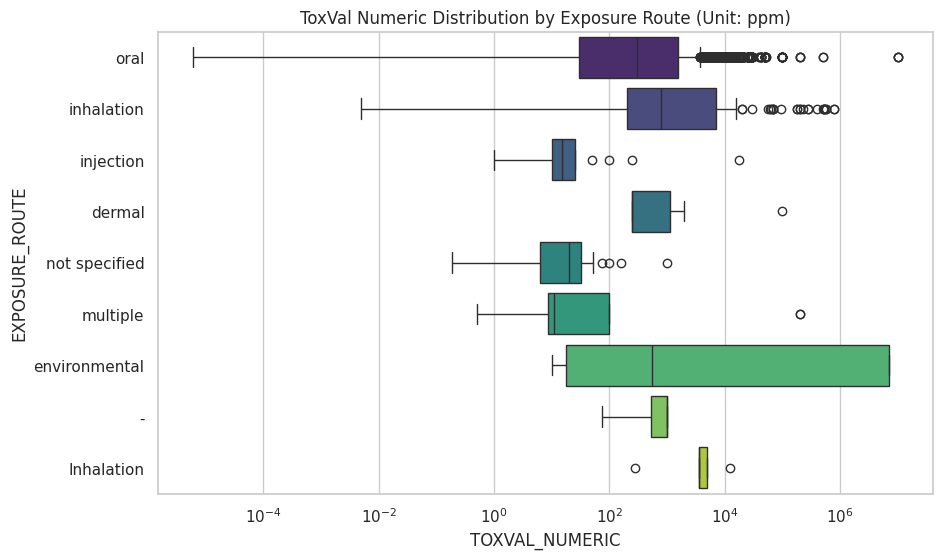

In [7]:
# Filter for top 5 units from updated df
if 'TOXVAL_UNITS' in df.columns and 'TOXVAL_NUMERIC' in df.columns:
    top_units = df['TOXVAL_UNITS'].value_counts().nlargest(5).index

    for unit in top_units:
        unit_df = df[df['TOXVAL_UNITS'] == unit]
        if 'EXPOSURE_ROUTE' in unit_df.columns and unit_df['EXPOSURE_ROUTE'].nunique() > 1:
            plt.figure(figsize=(10, 6))
            sns.boxplot(data=unit_df, x='TOXVAL_NUMERIC', y='EXPOSURE_ROUTE', palette="viridis")
            plt.xscale('log')
            plt.title(f"ToxVal Numeric Distribution by Exposure Route (Unit: {unit})")
            plt.show()

## 7. Keep only mammals

In [8]:
df = df[df['SPECIES_SUPERCATEGORY'] == 'Mammals']

## 8. ToxVal Numeric: Physical and Biological Consistency

This analysis identifies potentially erroneous `TOXVAL_NUMERIC` values by checking physical limits (e.g., concentrations > 100%) and biological plausibility (e.g., doses > 100,000 mg/kg).

The "reasonableness" of a value depends on:
- **TOXVAL_UNITS**: Mass vs Concentration.
- **EXPOSURE_ROUTE**: Oral vs Inhalation.
- **TOXVAL_TYPE**: Lethal (LD50) vs No-Effect (NOAEL).

In [9]:
import pandas as pd
import numpy as np

# 1. Unified Normalization Factors for Mass/Concentration
mass_conv_sorted = [
    ('mg/kg-day', 1.0), ('mg/kg/day', 1.0), ('ug/kg-day', 0.001), ('ng/kg-day', 0.000001),
    ('mg/kg bw', 1.0), ('ug/kg bw', 0.001), ('ug/kg', 0.001), ('ng/kg', 0.000001),
    ('mg/kg', 1.0), ('g/kg', 1000.0), ('mg/g', 1000.0), ('ug/mg', 1.0)
]

def classify_toxval_unified(row):
    val = row['TOXVAL_NUMERIC']
    unit = str(row['TOXVAL_UNITS']).lower().strip()
    tox_type = str(row['TOXVAL_TYPE']).lower().strip()
    if pd.isnull(val): return None
    
    # --- EXCLUSIONS (Specialized Units/Types) ---
    # Skip Slope factors, Potency, Inverse metrics, and Inhalation mg/m3 (gases reach high levels)
    if '-1' in unit or '^-1' in unit or 'cancer' in tox_type or 'slope' in tox_type or 'mg/m3' in unit: 
        return None
    
    # --- PHYSICAL ERRORS (Absolutely Impossible) ---
    # Concentrations > 100% (or 1M ppm)
    if 'ppm' in unit and val > 1000000: return 'Error: Physical (> 100% conc)'
    pure_percent = ['%', '% v/v', '% diet', '% w/v', '% weight']
    if unit in pure_percent and val > 100: return 'Error: Physical (> 100% conc)'
    
    # Doses > 1,000,000 mg/kg (animal made of 100% poison)
    # 1. Check mg/kg equivalent
    multiplier = None
    for u_str, factor in mass_conv_sorted:
        if u_str in unit:
            multiplier = factor
            break
    if multiplier is not None:
        norm_val = val * multiplier
        if norm_val > 1000000: return 'Error: Physical (Dose > Animal Weight)'
        if norm_val > 100000: return 'Review: Suspicious (Dose > 100g/kg)'
        
    # --- BIOLOGICAL SUSPICION (Concentrations > 10%) ---
    # Includes mg/L (water) and ppm (diet) where 10% is extremely high for almost any hazard
    if ('mg/l' in unit or 'ppm' in unit) and val > 100000:
        return 'Review: Suspicious (Concentration > 10%)'
            
    return None

# Apply classification
df['TOXVAL_OUTLIER_FLAG'] = df.apply(classify_toxval_unified, axis=1)

outliers_found = df[df['TOXVAL_OUTLIER_FLAG'].notnull()]
print(f"Detected {len(outliers_found)} suspicious or erroneous ToxVal records.")
if not outliers_found.empty:
    # Show results sorted by magnitude for audit
    display(outliers_found.sort_values(by='TOXVAL_NUMERIC', ascending=False)[['NAME', 'TOXVAL_NUMERIC', 'TOXVAL_UNITS', 'TOXVAL_TYPE', 'EXPOSURE_ROUTE', 'TOXVAL_OUTLIER_FLAG', 'SOURCE']])
else:
    print("No outliers detected with the current refined filters.")

Detected 401 suspicious or erroneous ToxVal records.


,NAME,TOXVAL_NUMERIC,TOXVAL_UNITS,TOXVAL_TYPE,EXPOSURE_ROUTE,TOXVAL_OUTLIER_FLAG,SOURCE
293792,Nitrocellulose,2.500000e+09,mg/kg soil,screening level (industrial soil),multiple,Error: Physical (Dose > Animal Weight),RSL
289984,Nitrocellulose,2.500000e+08,mg/kg soil,screening level (industrial soil),multiple,Error: Physical (Dose > Animal Weight),RSL
293791,Nitrocellulose,1.900000e+08,mg/kg soil,screening level (residential soil),multiple,Error: Physical (Dose > Animal Weight),RSL
293366,Hydrochloric acid,1.200000e+08,mg/kg soil,screening level (industrial soil),multiple,Error: Physical (Dose > Animal Weight),RSL
294628,Triacetin,6.600000e+07,mg/kg soil,screening level (industrial soil),multiple,Error: Physical (Dose > Animal Weight),RSL
...,...,...,...,...,...,...,...
296891,Egg white,1.010000e+05,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),TEST
296893,Egg white,1.010000e+05,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),TEST
39758,"2,2\'-{Oxybis[(ethane-2,1-diyl)oxy(1-hydroxyet...",1.000700e+05,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),ChemIDplus
39759,"2,2\'-{Oxybis[(ethane-2,1-diyl)oxy(1-hydroxyet...",1.000700e+05,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),ChemIDplus


## 9. Final Data Cleaning and Export

Identify and remove rows flagged as biological outliers, plant-related, or suspicious/erroneous based on the criteria in sections 5, 7, and 8. The final cleaned dataset is saved to a CSV file.

In [ ]:
# Define masks based on criteria in sections 5, 7, and 8
bio_outliers_mask = (df['STUDY_DURATION_YEARS'] > df['SPECIES_COMMON'].map(lifespan_map))
suspicious_mask = df['TOXVAL_OUTLIER_FLAG'].notnull()

# Keep only 'experimental' records
non_experimental_mask = (df['EXPERIMENTAL_RECORD'] != "experimental")

# Eliminate rows with 'Human'
human_mask = df['SPECIES_COMMON'].str.contains("Human", na=False)

# Eliminate specific species: Sheep, Rhesus Macaque, Mink, Gerbil
to_eliminate = ["Sheep", "Rhesus Macaque", "Mink", "Gerbil"]
eliminate_mask = df['SPECIES_COMMON'].isin(to_eliminate)

# 3. Combine all exclusion criteria
to_remove_mask = bio_outliers_mask | suspicious_mask | non_experimental_mask | human_mask | eliminate_mask

print(f"Rows to remove: {to_remove_mask.sum()}")
print(f" - Biological outliers: {bio_outliers_mask.sum()}")
print(f" - Suspicious/Error records: {suspicious_mask.sum()}")
print(f" - Non-experimental records: {non_experimental_mask.sum()}")
print(f" - Human records: {human_mask.sum()}")
print(f" - Other eliminated species: {eliminate_mask.sum()}")

# 4. Drop flagged rows and remove redundant column
df_cleaned = df[~to_remove_mask].copy()
df_cleaned = df_cleaned.drop(columns=['EXPERIMENTAL_RECORD'])

# 5. Species name transformations
species_map = {
    "Western European House Mouse": "Mouse",
    "House Mouse": "Mouse",
    "Mouse, Rat": "Rat",
    "Guinea Pig, Rat": "Rat"
}
df_cleaned['SPECIES_COMMON'] = df_cleaned['SPECIES_COMMON'].replace(species_map)

# 6. Save final cleaned dataset to CSV
output_csv = '../outputs/ToxValDB_v9.7.0_Cleaned_01.tsv'
df_cleaned.to_csv(output_csv, index=False)
print(f"\nCleaned dataset saved to: {output_csv}")
print(f"Final dataset shape: {df_cleaned.shape}")

Rows to remove: 114379
 - Biological outliers: 8
 - Suspicious/Error records: 401
 - Non-experimental records: 114041
 - Human records: 56559
 - Other eliminated species: 79

Cleaned dataset saved to: ../outputs/ToxValDB_v9.7.0_Cleaned_01_negatives.tsv
Final dataset shape: (363615, 35)
